# Marbled paper

Paper marbling floats drops of paint on water, then drags a comb through them. Both steps have
neat mathematical versions. A new drop pushes every point already on the surface straight out
from its center, making room for itself. A comb drags points along its direction, strongly near
each tine and barely at all in between. Here both are periodic, so the marbled sheet wraps
around as a seamless fabric tile.

In [1]:
import math
import random

from common import polygon
from nbturtle import render

W = H = 800
INK = "#0f1216"
COLORS = ["#15454d", "#c9a24a", "#e6dfcf", "#2a6b73", "#8a7340", "#0f1216"]
SEED = 12
BIG, SMALL = 16, 44
POINTS = 360

## A drop

`drop_map` moves one point when a drop of radius `r` lands at `(cx, cy)`. A point at distance
`d` moves out to √(d² + r²), which leaves exactly a disc of radius `r` free for the new paint.
Past 2 `r` the push fades, and at 4 `r` it stops, so a drop only ever moves points around the
nearest of its copies in the neighbouring tiles. That is what makes the marbling wrap.

In [2]:
def drop_map(px, py, cx, cy, r):
    # a drop of radius r at (cx, cy) pushes a point outward; influence ends at 4 r
    rc, r1 = 4 * r, 2 * r
    for dx in (-W, 0, W):
        for dy in (-H, 0, H):
            ox, oy = cx + dx, cy + dy
            d = math.hypot(px - ox, py - oy)
            if d >= rc or d < 1e-9:
                continue
            w = 1 if d <= r1 else 0.5 * (1 + math.cos(math.pi * (d - r1) / (rc - r1)))
            nd = d + (math.sqrt(d * d + r * r) - d) * w
            return (ox + (px - ox) * nd / d, oy + (py - oy) * nd / d)
    return (px, py)

## Sixty drops

16 big drops and 44 small ones, in six colors. Each new drop first pushes all the earlier ones
aside, then joins them as a circle of 360 points. `paint` fills every drop at each offset where
it reaches into the tile.

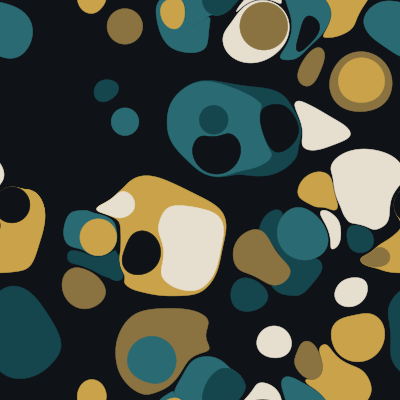

In [3]:
def make_drops():
    drops = []
    for n in range(BIG + SMALL):
        r = random.uniform(70, 100) if n < BIG else random.uniform(25, 55)
        cx, cy = random.uniform(-W / 2, W / 2), random.uniform(-H / 2, H / 2)
        for _, pts in drops:
            for k, (px, py) in enumerate(pts):
                pts[k] = drop_map(px, py, cx, cy, r)
        circle = [(cx + r * math.cos(2 * math.pi * k / POINTS), cy + r * math.sin(2 * math.pi * k / POINTS))
                  for k in range(POINTS)]
        drops.append((COLORS[n % len(COLORS)], circle))
    return drops


def paint(t, drops):
    for color, pts in drops:
        xs, ys = [p[0] for p in pts], [p[1] for p in pts]
        for dx in (-W, 0, W):
            for dy in (-H, 0, H):
                if (max(xs) + dx < -W / 2 or min(xs) + dx > W / 2
                        or max(ys) + dy < -H / 2 or min(ys) + dy > H / 2):
                    continue
                polygon(t, [(x + dx, y + dy) for x, y in pts], color)


random.seed(SEED)
drops = make_drops()
render(lambda t: paint(t, drops), W, H, INK, dpi=36)

## Combing

`comb` drags every point along y (a vertical comb) or along x (a horizontal one). Each tine pulls
hardest at its own position and falls off with the periodic bump `exp(-alpha * (1 - cos(…)))`;
a larger `alpha` makes a narrower tine. The first pass has 22 narrow tines, pulling 70 px down:

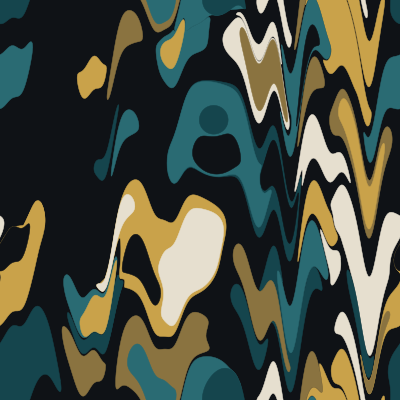

In [4]:
def comb(drops, vertical, tines, amplitude, alpha):
    # vertical combs drag along y with tines at fixed x; horizontal combs the other way
    period = W if vertical else H
    offsets = [random.uniform(0, period) + k * period / tines for k in range(tines)]
    for _, pts in drops:
        for k, (x, y) in enumerate(pts):
            s = x if vertical else y
            pull = amplitude * sum(math.exp(-alpha * (1 - math.cos(2 * math.pi * (s - o) / period)))
                                   for o in offsets)
            pts[k] = (x, y - pull) if vertical else (x + pull, y)


comb(drops, True, 22, 70, 60)
render(lambda t: paint(t, drops), W, H, INK, dpi=36)

## The finished sheet

A broad horizontal pass and a second vertical one finish it. `draw` repeats every step from the
seed, so it gives the same sheet no matter which cells above ran how often.

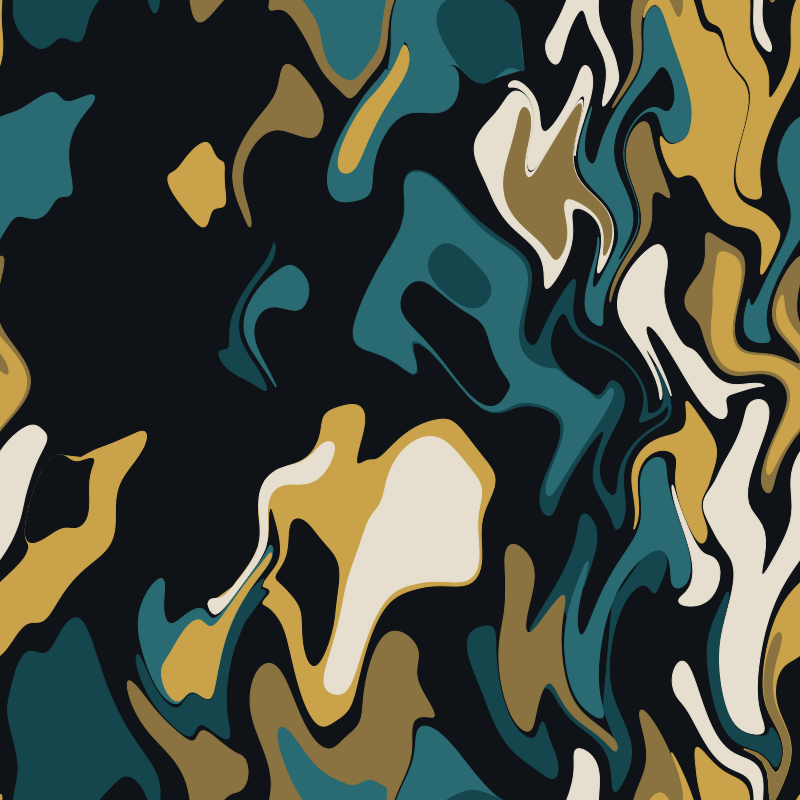

In [5]:
def draw(t):
    random.seed(SEED)
    drops = make_drops()
    comb(drops, True, 22, 70, 60)
    comb(drops, False, 6, 38, 10)
    comb(drops, True, 9, 28, 14)
    paint(t, drops)


canvas = render(draw, W, H, INK)
canvas

## Does it repeat?

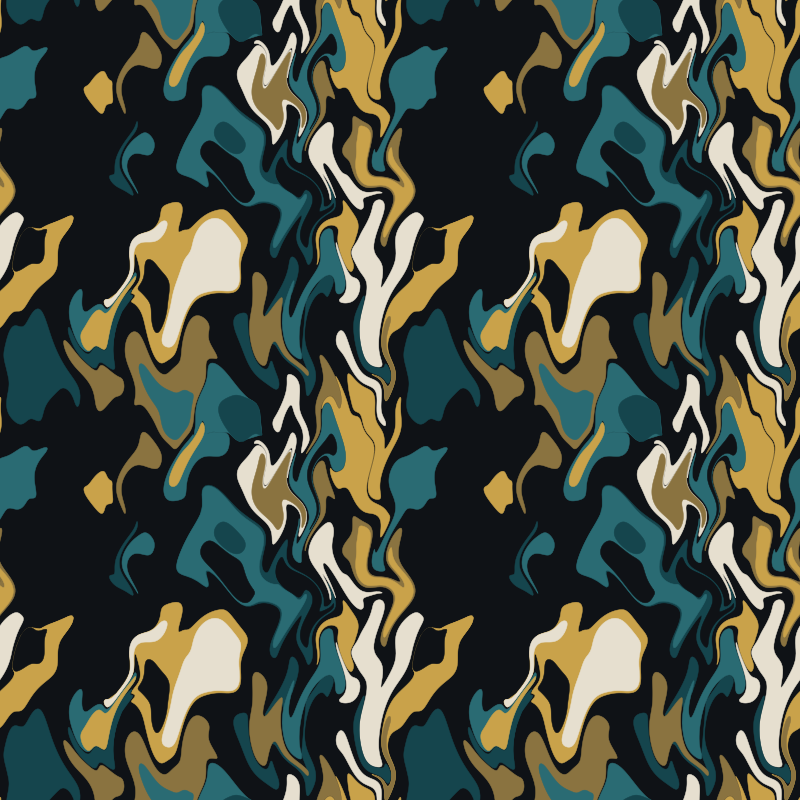

In [6]:
canvas.repeat()

## Try

- Another `SEED` marbles a sheet nobody has seen.
- Fewer, bigger drops: `BIG, SMALL = 8, 10`.
- One more pass with many fine tines, `comb(drops, False, 30, 20, 80)`, before `paint`.